## Error estimation

In this notebook, I will show several ways to calculate error bars in hera_pspec, which include:
1. Analytic error bars derived in quadratic estimator formalism. The input covariance will be shown tow options: 
from time average or from autobaseline visibilities   
2. Analytic noise power spectrum, while a input system temperature input needed.

Note the error bars shown in the notebook don't have true meanings, just serve as exmples for tutoring. 

In [1]:
%matplotlib inline
import os

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from pyuvdata import UVData

import hera_pspec as hp
from hera_pspec.data import DATA_PATH

## Prepare power spectrum

In [2]:
dfile = os.path.join(DATA_PATH, "zen.all.xx.LST.1.06964.uvA")

# Load into UVData objects
uvd = UVData()
uvd.read_miriad(dfile)

In [3]:
cosmo = hp.conversions.DEFAULT_COSMOLOGY
beamfile = os.path.join(DATA_PATH, "HERA_NF_dipole_power.beamfits")
uvb = hp.pspecbeam.PSpecBeamUV(beamfile, cosmo=cosmo)
# find conversion factor from Jy to mK
Jy_to_mK = uvb.Jy_to_mK(np.unique(uvd.freq_array) * u.Hz, pol="XX")

# reshape to appropriately match a UVData.data_array object and multiply in!
uvd.data_array *= Jy_to_mK[None, :, None]

In [4]:
# We set the number of samples (integrations) per visibility/frequency/time to be one here
uvd.nsample_array = np.ones_like(uvd.nsample_array)

In [5]:
# slide the time axis of uvd by one integration
uvd1 = uvd.select(times=np.unique(uvd.time_array)[:-1:2], inplace=False)
uvd2 = uvd.select(times=np.unique(uvd.time_array)[1::2], inplace=False)

# Create a new PSpecData object, and don't forget to feed the beam object
ds = hp.PSpecData(dsets=[uvd1, uvd2], wgts=[None, None], beam=uvb)

In [6]:
ds.rephase_to_dset(0)
# change units of UVData objects
ds.dsets[0].vis_units = "mK"
ds.dsets[1].vis_units = "mK"

In [7]:
baselines = [(24, 25), (37, 38), (38, 39)]
# calculate all baseline pairs from group
baselines1, baselines2, blpairs = hp.utils.construct_blpairs(
    baselines, exclude_auto_bls=True, exclude_permutations=True
)

### Using default norm:

In [8]:
uvp = ds.pspec(
    baselines1,
    baselines2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400)],
    input_data_weight="identity",
    norm="I",
    store_cov=True,
    cov_model="empirical",
    taper="blackman-harris",
    verbose=False,
)
uvp_q = ds.pspec(
    baselines1,
    baselines2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400)],
    input_data_weight="identity",
    norm="I",
    store_cov=True,
    cov_model="autos",
    taper="blackman-harris",
    verbose=False,
)

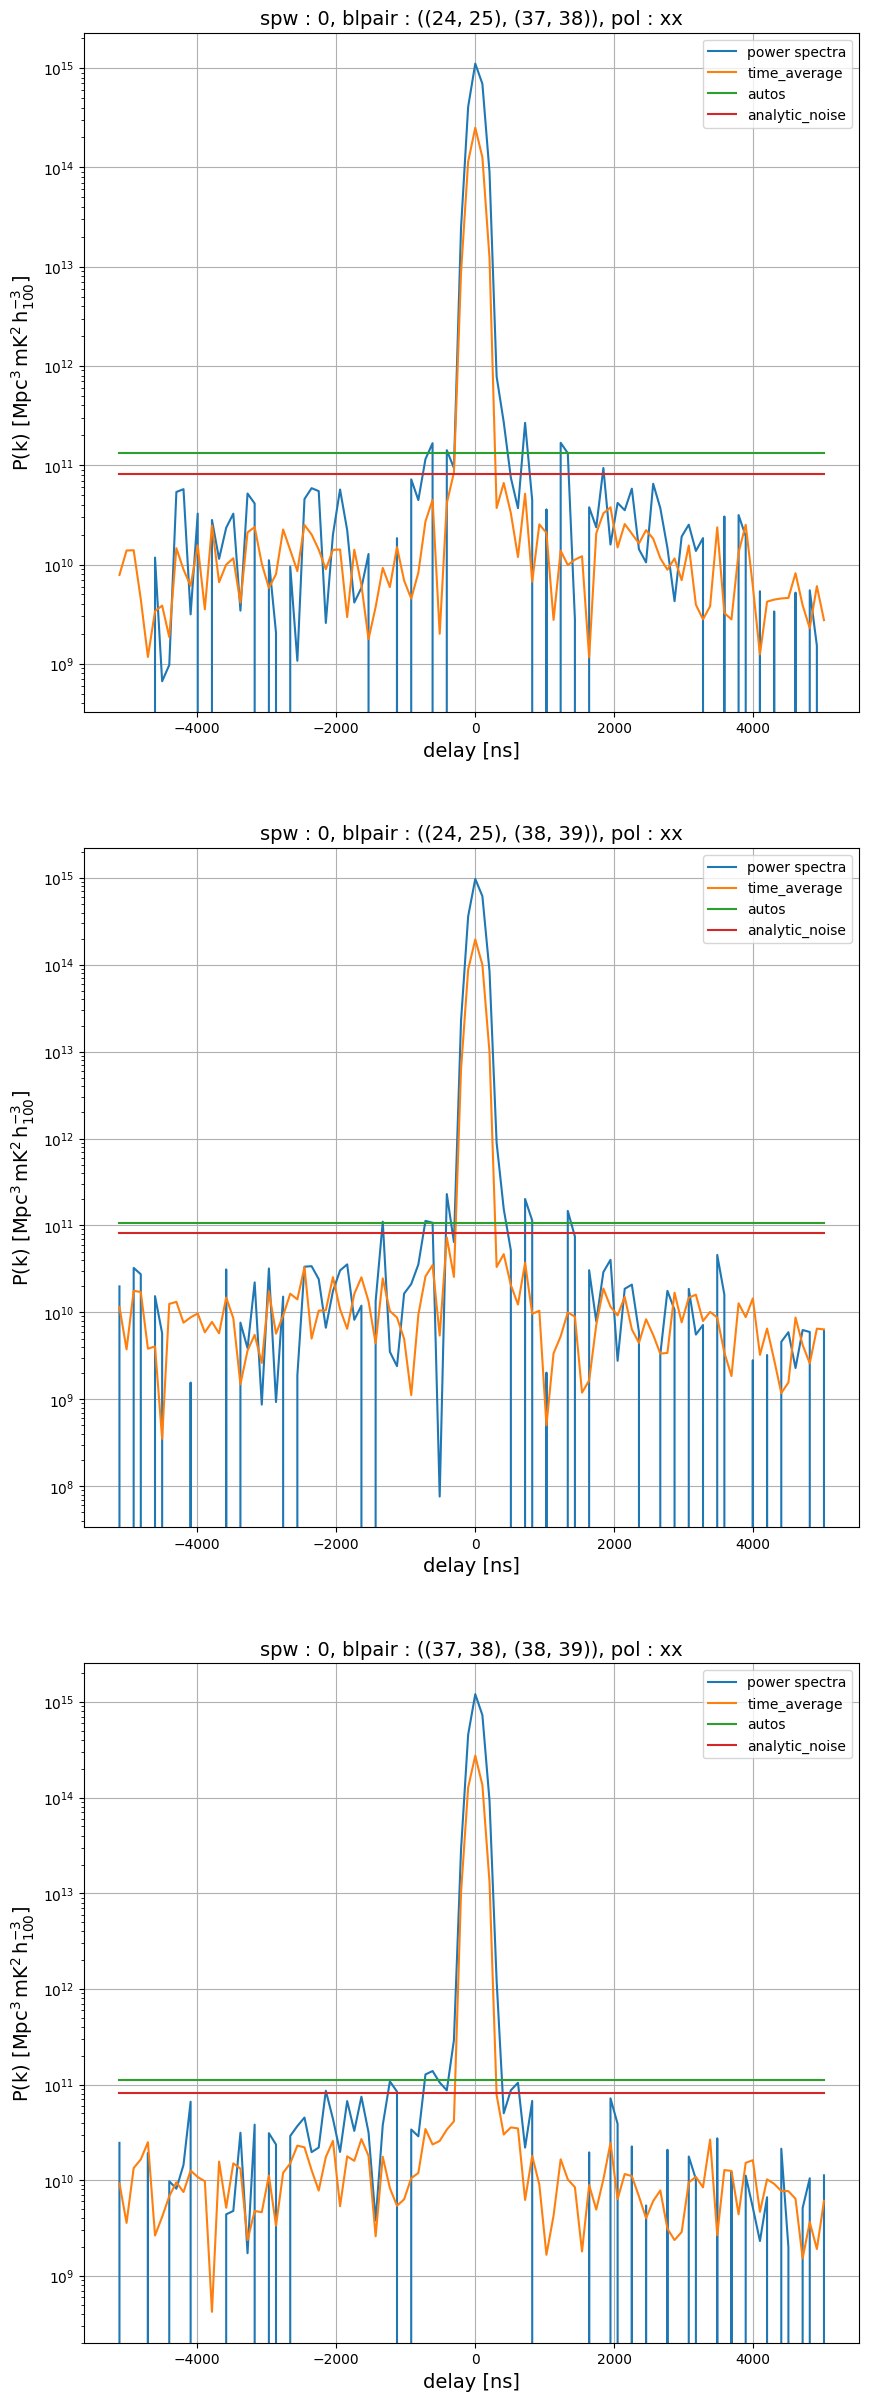

In [9]:
fig, axes = plt.subplots(figsize=(10, 30), nrows=3)
spw = 0
dlys = uvp.get_dlys(spw).to_value(u.ns)
time_index = 0
Tsys = 220 * u.K
## The system temperature here is not the true system temperature, just an arbitrary input.

for ax_idx in range(3):
    ax = axes[ax_idx]
    blp = blpairs[ax_idx]
    key = (spw, blp, "xx")
    ax.plot(dlys, np.real(uvp.get_data(key))[time_index], label="power spectra")
    ax.plot(
        dlys,
        np.sqrt(np.abs(np.diag(uvp.get_cov(key, component="real")[time_index]))),
        label="time_average",
    )
    ax.plot(
        dlys,
        np.sqrt(np.abs(np.diag(uvp_q.get_cov(key, component="real")[time_index]))),
        label="autos",
    )
    ax.plot(
        dlys,
        uvp.generate_noise_spectra(key[0], key[2], Tsys)[uvp.antnums_to_blpair(key[1])][
            time_index
        ],
        label="analytic_noise",
    )
    ax.set_yscale("log")
    ax.grid()
    ax.set_xlabel("delay [ns]", fontsize=14)
    ax.set_ylabel(f"P(k) [{uvp.units:latex_inline}]", fontsize=14)
    ax.set_title("spw : {}, blpair : {}, pol : {}".format(*key), fontsize=14)
    ax.legend(loc="best")

The error bars shown above are just for the purpose of code-running examples. 

### Using exact norm:

In [10]:
uvp_exact_norm = ds.pspec(
    baselines1,
    baselines2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400)],
    input_data_weight="identity",
    norm="I",
    store_cov=True,
    exact_norm=True,
    cov_model="empirical",
    taper="blackman-harris",
    verbose=False,
)
uvp_exact_norm_q = ds.pspec(
    baselines1,
    baselines2,
    (0, 1),
    [("xx", "xx")],
    spw_ranges=[(300, 400)],
    input_data_weight="identity",
    norm="I",
    store_cov=True,
    exact_norm=True,
    cov_model="autos",
    taper="blackman-harris",
    verbose=False,
)

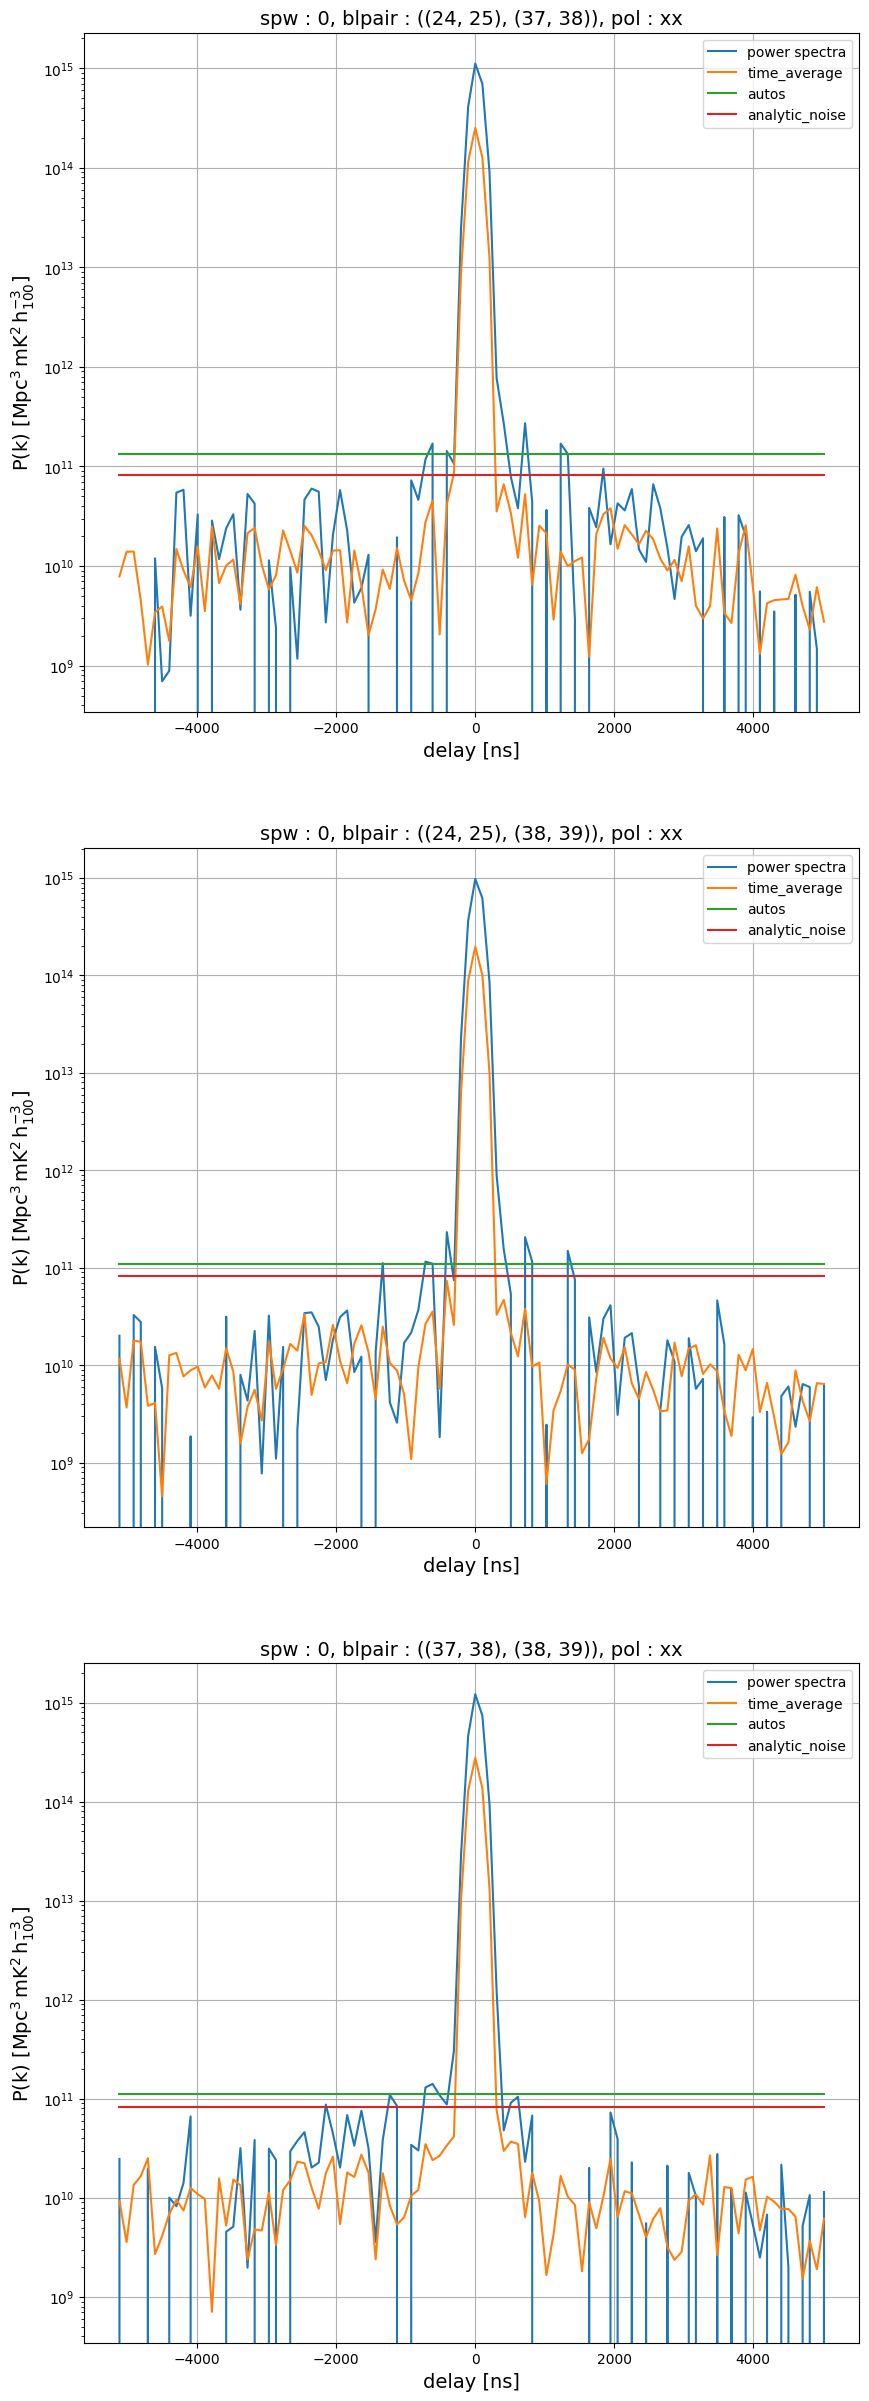

In [11]:
fig, axes = plt.subplots(figsize=(10, 30), nrows=3)
spw = 0
dlys = uvp_exact_norm.get_dlys(spw).to_value(u.ns)
time_index = 0
Tsys = 220 * u.K
## The system temperature here is not the true system temperature, just an arbitrary input.

for ax_idx in range(3):
    ax = axes[ax_idx]
    blp = blpairs[ax_idx]
    key = (spw, blp, "xx")
    ax.plot(
        dlys, np.real(uvp_exact_norm.get_data(key))[time_index], label="power spectra"
    )
    ax.plot(
        dlys,
        np.sqrt(
            np.abs(np.diag(uvp_exact_norm.get_cov(key, component="real")[time_index]))
        ),
        label="time_average",
    )
    ax.plot(
        dlys,
        np.sqrt(
            np.abs(np.diag(uvp_exact_norm_q.get_cov(key, component="real")[time_index]))
        ),
        label="autos",
    )
    ax.plot(
        dlys,
        uvp_exact_norm.generate_noise_spectra(key[0], key[2], Tsys)[
            uvp_exact_norm.antnums_to_blpair(key[1])
        ][time_index],
        label="analytic_noise",
    )
    ax.set_yscale("log")
    ax.grid()
    ax.set_xlabel("delay [ns]", fontsize=14)
    ax.set_ylabel(f"P(k) [{uvp_exact_norm.units:latex_inline}]", fontsize=14)
    ax.set_title("spw : {}, blpair : {}, pol : {}".format(*key), fontsize=14)
    ax.legend(loc="best")

The error bars shown above are just for the purpose of code-running examples. 